# Assignment 7: The Pacific Decadal Oscillation with PCA

In the Week 7 tutorial, PCA applied to tropical Pacific sea surface temperature (SST) found El Niño on its own. This assignment asks you to do the same thing for a different and slower pattern, the **Pacific Decadal Oscillation** (PDO), in the North Pacific.

You do not need a climate background for this. Here is everything you need to know about the PDO. It is a pattern of sea surface temperature in the North Pacific that switches sign every few decades. In its positive phase the water along the west coast of North America is warmer than normal and the central North Pacific is cooler than normal. In its negative phase the pattern is reversed. It matters because it shifts rainfall over the western United States and the productivity of Pacific fisheries for years at a time. It was discovered in 1997 by a group studying salmon catches, and they defined it exactly the way you will compute it: **the first principal component of North Pacific SST anomalies, after the global mean SST anomaly has been removed.**

That last step is the point of the assignment. You will run PCA twice, once without removing the global mean and once with, and see what changes. Along the way you will test your result against the official index, relate it to the ENSO index from the tutorial, and check whether the pattern holds up on years it was not fitted to.

You may reuse code from the tutorial, including the `to_matrix` and `to_map` helpers. Keep written answers short: two or three sentences is enough.

**Data.** The same NOAA ERSST v5 monthly SST field as the tutorial, read from a copy on the class server. The cells below load the global field for 1950 to 2024.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [4]:
# %pip install netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 40.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [netCDF4]
Note: you may need to restart the kernel to use updated packages.


In [9]:
# DATA = "/data9/CLMT5120/data/shr/sst.mnmean.nc"     # NOAA ERSST v5, copied to the class server
DATA = "sst.mnmean.nc"     # Downloaded to the same directory on my personal device
sst = xr.open_dataset(DATA)["sst"].sel(time=slice("1950", "2024")).load()
print(sst.shape, "= (months, latitudes, longitudes)")
sst.head

(900, 89, 180) = (months, latitudes, longitudes)


<bound method DataArray.head of <xarray.DataArray 'sst' (time: 900, lat: 89, lon: 180)> Size: 58MB
array([[[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
...
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan

## Part 1: Anomalies and the North Pacific

1) Compute monthly SST anomalies for the whole globe by subtracting, from each month, the 1950 to 2024 mean for that calendar month. Then select the North Pacific, **20N to 70N and 120E to 260E**, and plot the anomaly map for **January 2015**. This was the peak of a famous marine heat wave, so the map should show a large warm patch.

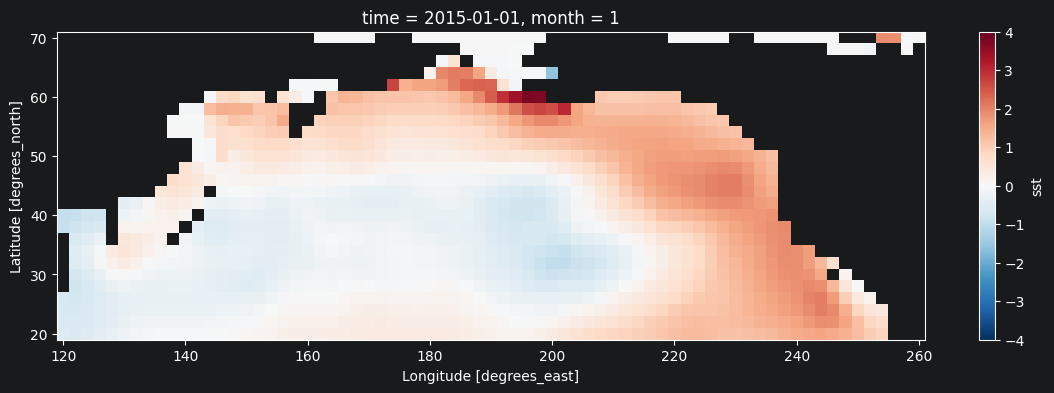

In [26]:
clim = sst.groupby('time.month').mean('time') # Mean for each month across the years
anom = sst.groupby('time.month') - clim

north_pacific_anom = anom.sel(lat=slice(70, 20), lon=slice(120, 260))
fig, axes = plt.subplots(figsize=(14,4))
north_pacific_anom.sel(time='2015-01').squeeze().plot(cmap='RdBu_r', vmin=-4, vmax=4)
plt.show()

2) Turn the North Pacific anomaly field into a matrix of months by ocean grid cells, with the land cells dropped and each cell weighted by the square root of the cosine of its latitude. Report the shape and the number of land cells dropped. Also write the function that puts a vector back on the map, since you will need it for every EOF plot.

In [21]:
# Apply weighting to prevent the high latitude cells from being overweighted
weight = np.sqrt(np.cos(np.deg2rad(north_pacific_anom.lat)))

def to_matrix(field):
    flat = (field*weight).values.reshape(field.shape[0], -1) # Reshapes lat lon into just one dimension, converting a 3D matrix into a 2D matrix of time vs coordinate
    ocean = ~np.isnan(flat[0]) #Land is nan so ocean is not is nan - boolean mask of ocean
    return flat[:, ocean], ocean

def to_map(vector, ocean):
    full = np.full(ocean.size, np.nan) # Creates one dimension that is full of nans
    full[ocean] = vector
    return xr.DataArray(full.reshape(north_pacific_anom.shape[1:]), coords={'lat': north_pacific_anom.lat, 'lon': north_pacific_anom.lon}) / weight

X_anom, ocean = to_matrix(north_pacific_anom)

print('matrix: ', X_anom.shape)
print('dropped: ', (~ocean).sum())

matrix:  (900, 1231)
dropped:  615


## Part 2: First attempt, straight from the anomalies

3) Fit a PCA with 10 components on this matrix. Print the fraction of variance explained by the first four components, plot the first EOF as a map, and plot the first PC as a time series with a 12-month running mean on top of it.

In [22]:
pca = PCA(n_components=10).fit(X_anom)
pcs = pca.transform(X_anom) # 900 months by 10 components
eofs = pca.components_ # The spatial patterns

evr = pca.explained_variance_ratio_
print('variance explained', evr[:4])


variance explained [0.21827222 0.18958123 0.08589877 0.06315698]


/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encounter

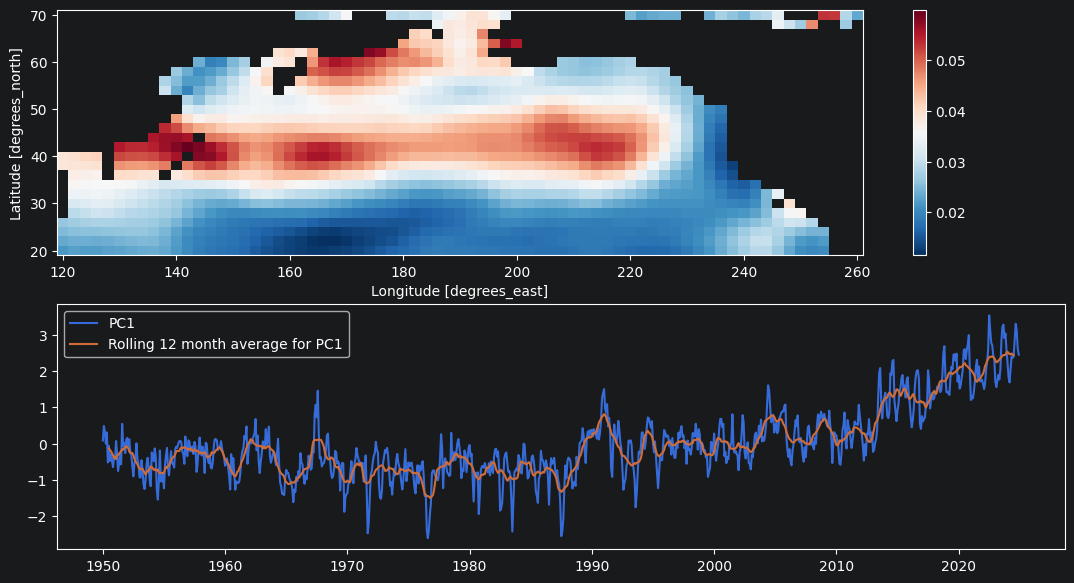

In [31]:
eof1_map = to_map(eofs[0], ocean)

pc1 = pcs[:, 0] / pcs[:, 0].std() # All times but just the first component, rescale
pc1 = xr.DataArray(pc1, coords={'time': north_pacific_anom.time}, dims='time')
mean_12_month = pc1.rolling(time=12, center=True).mean() # Rolling mean of 12 months

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
eof1_map.plot(ax=axes[0], cmap = 'RdBu_r')
axes[1].plot(north_pacific_anom.time, pc1, label='PC1')
axes[1].plot(mean_12_month.time, mean_12_month, label='Rolling 12 month average for PC1')
axes[1].legend()

4) Compute the correlation between PC1 and time (a simple counter, `np.arange(len(pc1))`, will do). Then look at the variance explained by the first and second components. When two components explain almost the same fraction of the variance, PCA cannot separate them reliably, and each pattern is a mixture of the two. Is that the case here? Answer with the two numbers.

In [39]:
time = np.arange(len(pc1))
corr = np.corrcoef(pc1, time)[0, 1]

print('correlation: ' + str(corr))
print('variance explained by pca1: ' + str(evr[0]))
print('variance explained by pca2: ' + str(evr[1]))
print('Since PCA1 and PCA 2 are similar, PCA cannot separate them reliably')

correlation: 0.661188153158533
variance explained by pca1: 0.21827222
variance explained by pca2: 0.18958123
Since PCA1 and PCA 2 are similar, PCA cannot separate them reliably


## Part 3: Remove the global mean

5) Compute the global mean SST anomaly for each month, weighted by the cosine of latitude so that each grid cell counts in proportion to its area, and plot it. xarray's `weighted` method does this: `anom.weighted(np.cos(np.deg2rad(anom.lat))).mean(["lat", "lon"])`.

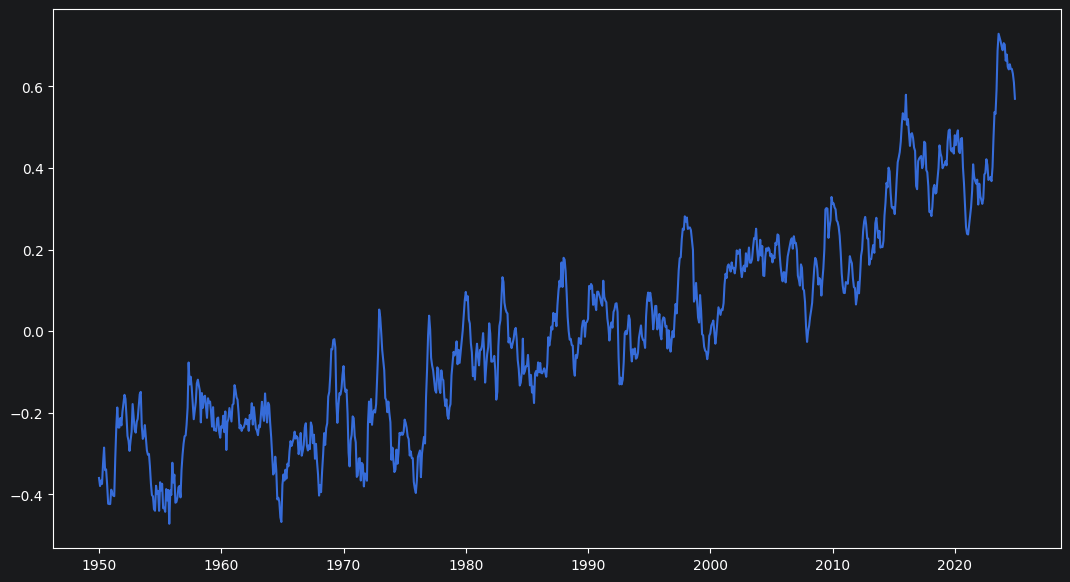

In [48]:
global_mean_anomaly = anom.weighted(np.cos(np.deg2rad(anom.lat))).mean(["lat", "lon"])
fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(global_mean_anomaly.time, global_mean_anomaly)
plt.show()

6) Subtract the global mean anomaly from every grid cell of the North Pacific anomalies, build the matrix again, fit a new PCA with 10 components, and repeat the plots from question 3: the variance explained by the first four components, the EOF 1 map, and PC1 with its 12-month running mean.

In [49]:
north_pacific_no_anom = north_pacific_anom - global_mean_anomaly
X_no_anom, ocean = to_matrix(north_pacific_no_anom)

pca_no_anom = PCA(n_components=10).fit(X_no_anom)
pcs_no_anom = pca_no_anom.transform(X_no_anom) # 900 months by 10 components
eofs_no_anom = pca_no_anom.components_ # The spatial patterns

evr_no_anom = pca_no_anom.explained_variance_ratio_
print('variance explained', evr_no_anom[:4])


variance explained [0.22488838 0.12678793 0.074006   0.06565116]


/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/deborah/Desktop/Masters/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encounter

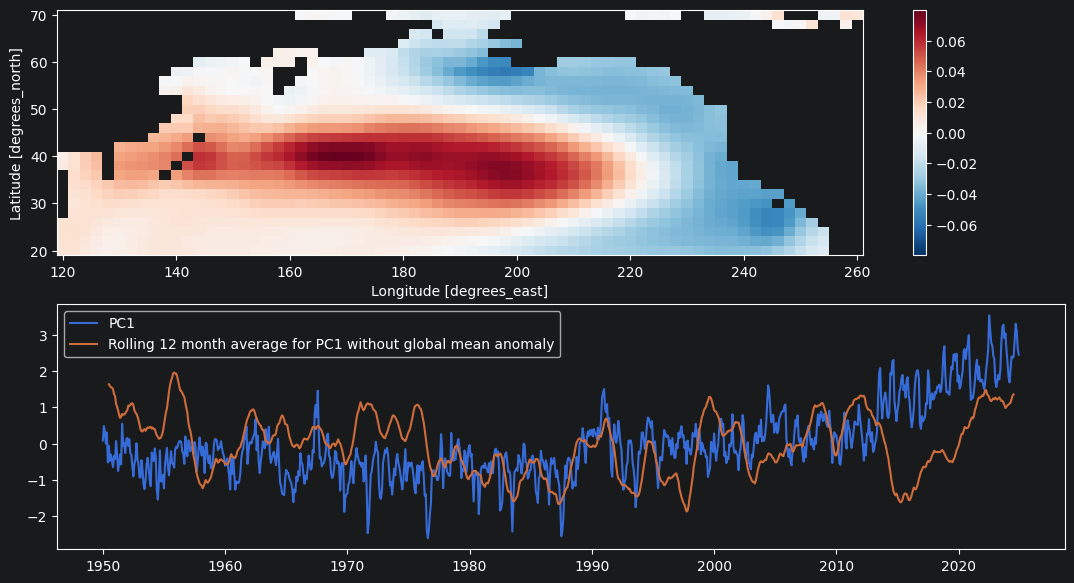

In [50]:
eof1_no_anom_map = to_map(eofs_no_anom[0], ocean)

pc1_no_anom = pcs_no_anom[:, 0] / pcs_no_anom[:, 0].std() # All times but just the first component, rescale
pc1_no_anom = xr.DataArray(pc1_no_anom, coords={'time': north_pacific_anom.time}, dims='time')
mean_12_month_no_anom = pc1_no_anom.rolling(time=12, center=True).mean() # Rolling mean of 12 months

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
eof1_no_anom_map.plot(ax=axes[0], cmap = 'RdBu_r')
axes[1].plot(north_pacific_anom.time, pc1, label='PC1')
axes[1].plot(mean_12_month_no_anom.time, mean_12_month_no_anom, label='Rolling 12 month average for PC1 without global mean anomaly')
axes[1].legend()

7) **Written answer.** Compare the two EOF 1 maps and the two PC1 time series. What did subtracting the global mean remove, and why does that make the first component easier to interpret? The tutorial's EOF 2 is a useful comparison.

## Part 4: Compare with the official index

NOAA publishes a PDO index computed from the same ERSST data. The cell below reads it from NOAA's server. If that fails, a copy named `ersst.v5.pdo.dat` is in `/data9/CLMT5120/data/shr/`.

In [ ]:
def read_pdo(path):
    rows = []
    for line in open(path) if not path.startswith("http") else pd.io.common.urlopen(path).read().decode().splitlines():
        parts = line.split()
        if len(parts) == 13 and parts[0].isdigit():
            for m, v in enumerate(parts[1:], 1):
                rows.append((pd.Timestamp(int(parts[0]), m, 1), float(v)))
    s = pd.Series(dict(rows)).sort_index()
    return s.where(s.abs() < 90)                  # 99.99 marks missing months

try:
    pdo_official = read_pdo("https://www.ncei.noaa.gov/pub/data/cmb/ersst/v5/index/ersst.v5.pdo.dat")
except Exception:
    pdo_official = read_pdo("/data9/CLMT5120/data/shr/ersst.v5.pdo.dat")
pdo_official = pdo_official["1950":"2024"]
print(pdo_official.head(3)); print(len(pdo_official), "months")

8) The sign of an EOF is arbitrary. Fix the sign of your PC1 from question 6 so that positive values mean **warm along the North American coast**, which is the convention for the PDO (check the loading of EOF 1 near 45N, 230E). Standardize it, plot it on the same axes as the official index, and report the correlation between the two.

9) Do the same for the first-attempt PC1 from question 3, with its sign fixed the same way, and report its correlation with the official index. Which attempt matches, and by how much?

## Part 5: The PDO and ENSO

10) Compute the Niño3.4 anomaly as in the tutorial: the anomaly averaged over 5S to 5N and 190E to 240E, from the global `anom` field (not the global-mean-removed one). Make a scatter plot of your PDO index against it, one point per month, and report the correlation.

11) **Written answer.** The two indices come from separate PCAs on different parts of the ocean, and yet they are correlated at about 0.5. In two or three sentences: what does that correlation tell you about the two patterns, and what does it not tell you?

## Part 6: Does the pattern hold up on years it was not fitted to?

PCA was fitted on all 75 years, so the pattern has seen every month it is being compared against. The Week 6 habit is to check on data the method never saw.

12) Fit a new PCA with 10 components on the global-mean-removed matrix using only **1950 to 1990**. Project all months onto it with `transform`, fix the sign the same way as before, and report the correlation of the resulting PC1 with the official index separately for 1950 to 1990 and for 1991 to 2024.

13) **Written answer.** Why is this a fair test of the pattern, and what would it have meant if the 1991 to 2024 correlation had come out much lower than the 1950 to 1990 one?

## What to hand in

The notebook with all cells run, and the three written answers (questions 7, 11, and 13) in their markdown cells. Keep the written answers to a few sentences each.